# Разведочный анализ Credit Risk Dataset

Анализ выполняется **только на исходной части** `data/initial/initial.csv` (60 % записей), чтобы порции новых данных не влияли на решения о подготовке признаков. Перед запуском: `python -m src.data.split_data`.

Ноутбук отвечает на вопросы, важные для задачи оценки риска дефолта:
1. Что содержится в наборе и какого типа признаки?
2. Насколько несбалансированы классы?
3. Какие есть проблемы качества: пропуски, дубликаты, выбросы, невозможные значения?
4. Как признаки связаны с дефолтом и между собой?
5. Какие признаки могут быть неизвестны в момент предсказания или раскрывать целевую переменную?
6. Подтверждаются ли предметные гипотезы H1–H5?

Рисунки сохраняются в `reports/figures`, числовая сводка — в `reports/eda_summary.json` (из них собирается отчет).

In [1]:
import json, os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from src.config import NUMERIC, CATEGORICAL, TARGET, load_params

P = load_params()
FIG = Path('reports/figures'); FIG.mkdir(parents=True, exist_ok=True)
C_OK, C_DEF, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df'
RU = {'person_age': 'Возраст, лет', 'person_income': 'Годовой доход', 'person_emp_length': 'Стаж работы, лет',
      'loan_amnt': 'Сумма кредита', 'loan_int_rate': 'Процентная ставка, %',
      'loan_percent_income': 'Доля платежа в доходе', 'cb_person_cred_hist_length': 'Кредитная история, лет',
      'person_home_ownership': 'Тип владения жильем', 'loan_intent': 'Цель кредита',
      'loan_grade': 'Рейтинг займа', 'cb_person_default_on_file': 'Дефолт в прошлом'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.edgecolor': MUTED,
                     'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
                     'figure.dpi': 150, 'savefig.bbox': 'tight'})

def save(fig, name):
    """Сохранить рисунок для отчета и показать его в ноутбуке."""
    fig.savefig(FIG / name)
    plt.show()

def rate_table(data, col):
    t = data.groupby(col, observed=True)[TARGET].agg(['mean', 'size'])
    return {str(k): {'default_rate': round(float(r['mean']), 4), 'n': int(r['size'])} for k, r in t.iterrows()}

df = pd.read_csv(P['data']['initial_file'])
s = {'rows': len(df), 'columns': df.shape[1]}   # сводка для отчета
df.shape

(19549, 12)

## 1. Структура набора

**Вопрос:** какие признаки есть в наборе, какого они типа и что означают?

In [2]:
s['dtypes'] = {c: str(t) for c, t in df.dtypes.items()}
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 19549 entries, 0 to 19548
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  19549 non-null  int64  
 1   person_income               19549 non-null  int64  
 2   person_home_ownership       19549 non-null  str    
 3   person_emp_length           18998 non-null  float64
 4   loan_intent                 19549 non-null  str    
 5   loan_grade                  19549 non-null  str    
 6   loan_amnt                   19549 non-null  int64  
 7   loan_int_rate               17691 non-null  float64
 8   loan_status                 19549 non-null  int64  
 9   loan_percent_income         19549 non-null  float64
 10  cb_person_default_on_file   19549 non-null  str    
 11  cb_person_cred_hist_length  19549 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 1.8 MB


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,45000,MORTGAGE,2.0,EDUCATION,D,8000,16.49,0,0.18,Y,4
1,36,24960,RENT,3.0,VENTURE,A,5000,6.62,0,0.20,N,15
2,26,16120,RENT,2.0,PERSONAL,B,5000,11.58,1,0.31,N,3
3,29,72000,MORTGAGE,5.0,PERSONAL,A,10000,6.17,0,0.14,N,10
4,28,25000,RENT,0.0,DEBTCONSOLIDATION,A,3000,5.42,0,0.12,N,6


**Вывод:** 11 входных признаков и целевая переменная `loan_status` (1 — дефолт, 0 — нет).
Числовые: возраст, годовой доход, стаж, сумма кредита, ставка, доля платежа в доходе, длина кредитной истории.
Категориальные: тип владения жильем, цель кредита, рейтинг займа (порядковый, A–G), дефолт в прошлом (Y/N). Категории записаны словами, справочник не нужен.

## 2. Целевая переменная

**Вопрос:** насколько несбалансированы классы и какую метрику нельзя использовать в одиночку?

{'counts': {'0': 15235, '1': 4314}, 'default_rate': 0.2207}


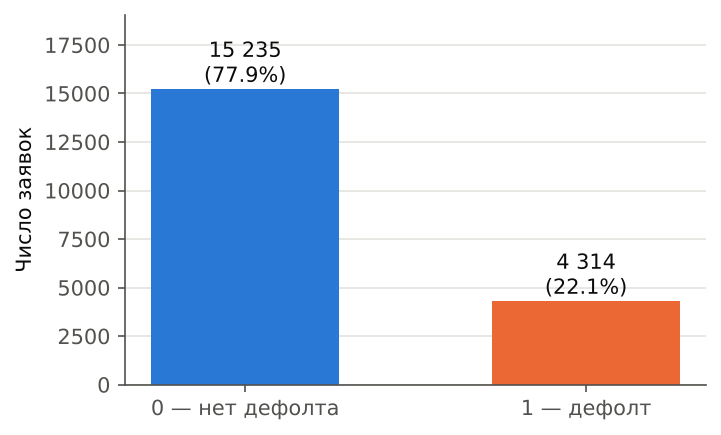

In [3]:
vc = df[TARGET].value_counts().sort_index()
s['target'] = {'counts': {str(k): int(v) for k, v in vc.items()}, 'default_rate': round(float(df[TARGET].mean()), 4)}
print(s['target'])

fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(['0 — нет дефолта', '1 — дефолт'], vc.values, color=[C_OK, C_DEF], width=0.55)
for b, v in zip(bars, vc.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f'{v:,}'.replace(',', ' ') + f'\n({v / len(df):.1%})',
            ha='center', va='bottom', color=INK)
ax.set_ylabel('Число заявок'); ax.set_ylim(0, vc.max() * 1.25); ax.grid(axis='x', visible=False)
save(fig, 'fig_target.png')

**Вывод:** дефолтов около 22 %, соотношение классов примерно 3,5 к 1. Модель, которая всегда отвечает «нет дефолта», получит около 78 % верных ответов и не найдет ни одной рискованной заявки. Поэтому нужны полнота и точность по классу «дефолт», F1 и ROC-AUC, а разделение train/test — со стратификацией.

## 3. Качество данных

**Вопрос:** какие есть пропуски, дубликаты, выбросы и физически невозможные значения?

In [4]:
s['missing'] = {c: int(v) for c, v in df.isna().sum().items() if v}
s['missing_share'] = {c: round(v / len(df), 4) for c, v in s['missing'].items()}
s['duplicates'] = int(df.duplicated().sum())
s['impossible'] = {
    'age_gt_100': int((df.person_age > 100).sum()),
    'emp_gt_60': int((df.person_emp_length > 60).sum()),
    'emp_gt_age_minus_14': int((df.person_emp_length > df.person_age - 14).sum()),
    'percent_income_mismatch': int(((df.loan_percent_income - df.loan_amnt / df.person_income).abs() > 0.011).sum()),
    'rate_out_5_25': int((~df.loan_int_rate.dropna().between(5, 25)).sum()),
}
print('Пропуски:', s['missing'], s['missing_share'])
print('Полных дубликатов:', s['duplicates'])
print('Невозможные и несогласованные значения:', s['impossible'])

Пропуски: {'person_emp_length': 551, 'loan_int_rate': 1858} {'person_emp_length': 0.0282, 'loan_int_rate': 0.095}
Полных дубликатов: 54
Невозможные и несогласованные значения: {'age_gt_100': 3, 'emp_gt_60': 1, 'emp_gt_age_minus_14': 1, 'percent_income_mismatch': 227, 'rate_out_5_25': 0}


In [5]:
s['describe'] = df[NUMERIC].describe(percentiles=[.25, .5, .75, .99]).round(2).to_dict()
q1, q3 = df[NUMERIC].quantile(.25), df[NUMERIC].quantile(.75); iqr = q3 - q1
s['iqr_outliers'] = {c: int(((df[c] < q1[c] - 1.5 * iqr[c]) | (df[c] > q3[c] + 1.5 * iqr[c])).sum()) for c in NUMERIC}
s['categories'] = {c: df[c].value_counts().to_dict() for c in CATEGORICAL}
print('Выбросы по правилу 1,5 IQR:', s['iqr_outliers'])
df[NUMERIC].describe(percentiles=[.25, .5, .75, .99]).T.round(2)

Выбросы по правилу 1,5 IQR: {'person_age': 911, 'person_income': 969, 'person_emp_length': 540, 'loan_amnt': 1022, 'loan_int_rate': 4, 'loan_percent_income': 391, 'cb_person_cred_hist_length': 682}


,count,mean,std,min,25%,50%,75%,99%,max
person_age,19549.0,27.77,6.38,20.00,23.00,26.00,30.00,50.00,144.00
person_income,19549.0,66105.87,54622.82,4200.00,39000.00,55000.00,79200.00,225000.00,2039784.00
person_emp_length,18998.0,4.82,4.14,0.00,2.00,4.00,7.00,18.00,123.00
loan_amnt,19549.0,9624.29,6345.18,500.00,5000.00,8000.00,12250.00,30000.00,35000.00
loan_int_rate,17691.0,11.01,3.24,5.42,7.90,10.99,13.47,18.53,23.22
loan_percent_income,19549.0,0.17,0.11,0.00,0.09,0.15,0.23,0.50,0.78
cb_person_cred_hist_length,19549.0,5.83,4.07,2.00,3.00,4.00,8.00,17.00,30.00


**Вывод:** пропуски есть только в стаже (около 3 %) и ставке (около 10 %) — их заполняем медианой внутри Pipeline. Полные дубликаты удаляем. Возраст 123–144 года и стаж 123 года физически невозможны — такие записи удаляем. В части записей `loan_percent_income` заметно меньше отношения суммы к доходу (до 0,09) — поля несогласованы, записи исключаем. Большие доходы и суммы — редкие, но допустимые значения: не удаляем, а логарифмируем и масштабируем. Эти выводы стали требованиями DQ-01…DQ-10 в `src/data/validate.py`.

## 4. Распределения признаков и связь с целевой переменной

**Вопрос:** какие числовые признаки различаются у заемщиков с дефолтом и без?

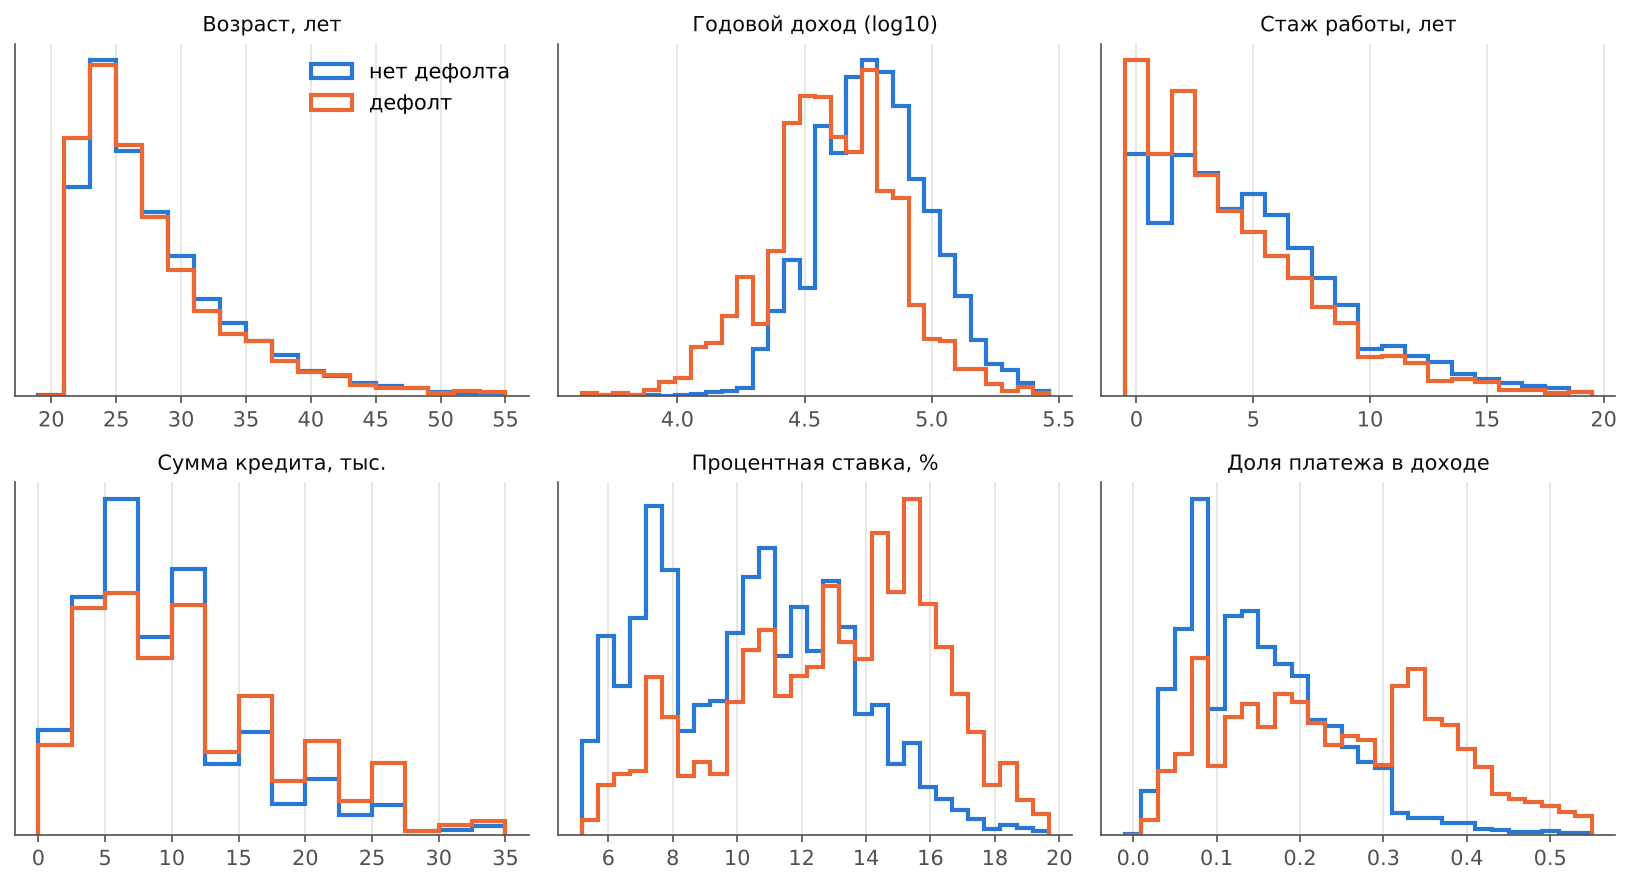

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
loan_status,,,,,,,
0,26.0,60000.0,4.0,8000.0,10.59,0.13,4.0
1,26.0,42000.0,3.0,9950.0,13.49,0.24,4.0


In [6]:
clean = df[(df.person_age <= 100) & ~(df.person_emp_length > 60)]   # без невозможных значений
cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income']
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, c in zip(axes.ravel(), cols):
    x = clean[c].dropna()
    if c == 'person_income':
        x = np.log10(x)
    # шаг корзин согласован с дискретностью значений, иначе появляются ложные пики
    step = {'person_age': 2, 'person_emp_length': 1, 'loan_amnt': 2500, 'loan_int_rate': 0.5, 'loan_percent_income': 0.02}.get(c)
    if c == 'loan_amnt':
        x = x / 1000; step = 2.5
    if step:
        start = 0 if c in ('loan_amnt', 'loan_percent_income') else x.min() - step / 2
        bins = np.arange(start - (step / 2 if c == 'loan_percent_income' else 0), x.quantile(0.995) + step, step)
    else:
        bins = np.histogram_bin_edges(x, bins=30, range=(x.min(), x.quantile(0.995)))
    for val, color, lab in ((0, C_OK, 'нет дефолта'), (1, C_DEF, 'дефолт')):
        ax.hist(x[clean.loc[x.index, TARGET] == val], bins=bins, density=True, histtype='step', linewidth=2, color=color, label=lab)
    ax.set_title(RU[c] + {'person_income': ' (log10)', 'loan_amnt': ', тыс.'}.get(c, ''), fontsize=10, color=INK)
    ax.set_yticks([])
axes[0, 0].legend(frameon=False)
fig.tight_layout()
save(fig, 'fig_numeric.png')

s['numeric_by_target_median'] = clean.groupby(TARGET)[NUMERIC].median().round(3).to_dict()
clean.groupby(TARGET)[NUMERIC].median().round(2)

**Вывод:** сильнее всего классы различаются по доле платежа в доходе (медиана 0,13 против 0,24), ставке и доходу (у дефолтных доход ниже). Возраст, стаж и длина кредитной истории у классов почти одинаковы. Доход и сумма кредита сильно скошены вправо.

**Вопрос:** как доля дефолтов зависит от категориальных признаков?

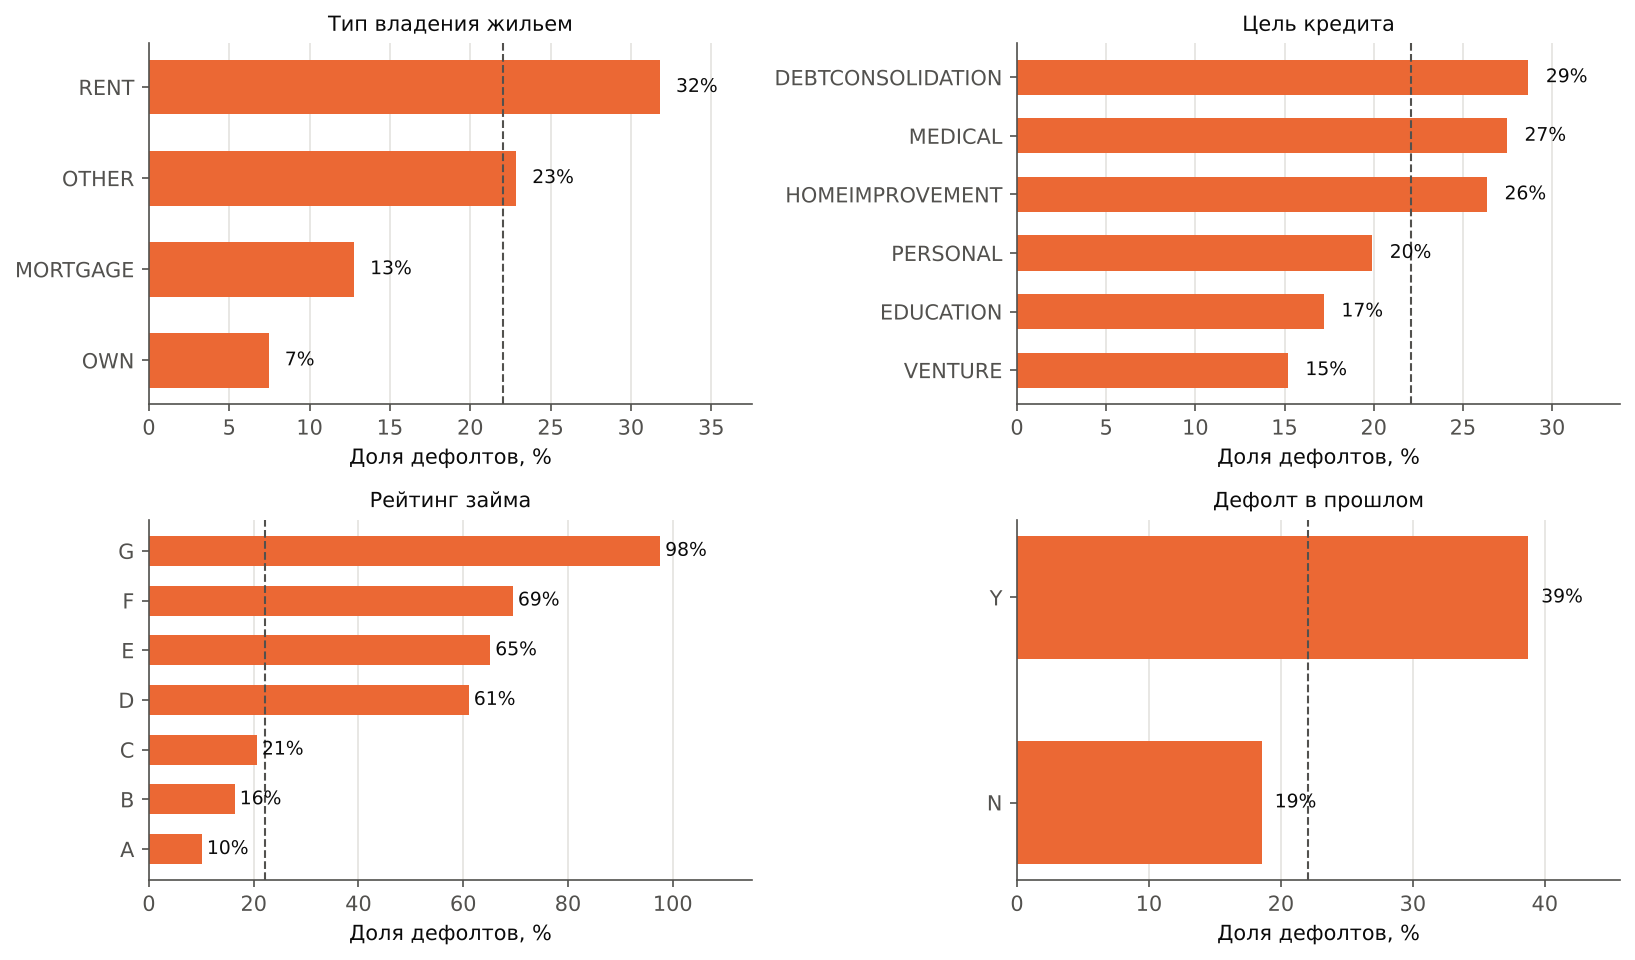

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, c in zip(axes.ravel(), CATEGORICAL):
    r = df.groupby(c)[TARGET].mean()
    r = r.sort_index() if c == 'loan_grade' else r.sort_values()
    bars = ax.barh(r.index.astype(str), r.values * 100, color=C_DEF, height=0.6)
    for b, v in zip(bars, r.values):
        ax.text(v * 100 + 1, b.get_y() + b.get_height() / 2, f'{v:.0%}', va='center', color=INK, fontsize=9)
    ax.axvline(df[TARGET].mean() * 100, color=MUTED, linestyle='--', linewidth=1)   # средняя доля
    ax.set_title(RU[c], fontsize=10, color=INK); ax.set_xlim(0, max(r.values) * 118)
    ax.set_xlabel('Доля дефолтов, %'); ax.grid(axis='y', visible=False)
    s.setdefault('default_rate_by', {})[c] = rate_table(df, c)
fig.tight_layout()
save(fig, 'fig_categorical.png')

**Вывод:** доля дефолтов растет почти монотонно от рейтинга A (около 10 %) к G (около 98 %). Арендаторы (RENT) дефолтят заметно чаще собственников и заемщиков с ипотекой. Дефолт в прошлом примерно вдвое повышает долю дефолтов. По цели кредита разброс меньше: от VENTURE до DEBTCONSOLIDATION.

## 5. Взаимосвязи между признаками

**Вопрос:** есть ли сильно связанные (дублирующие) признаки?

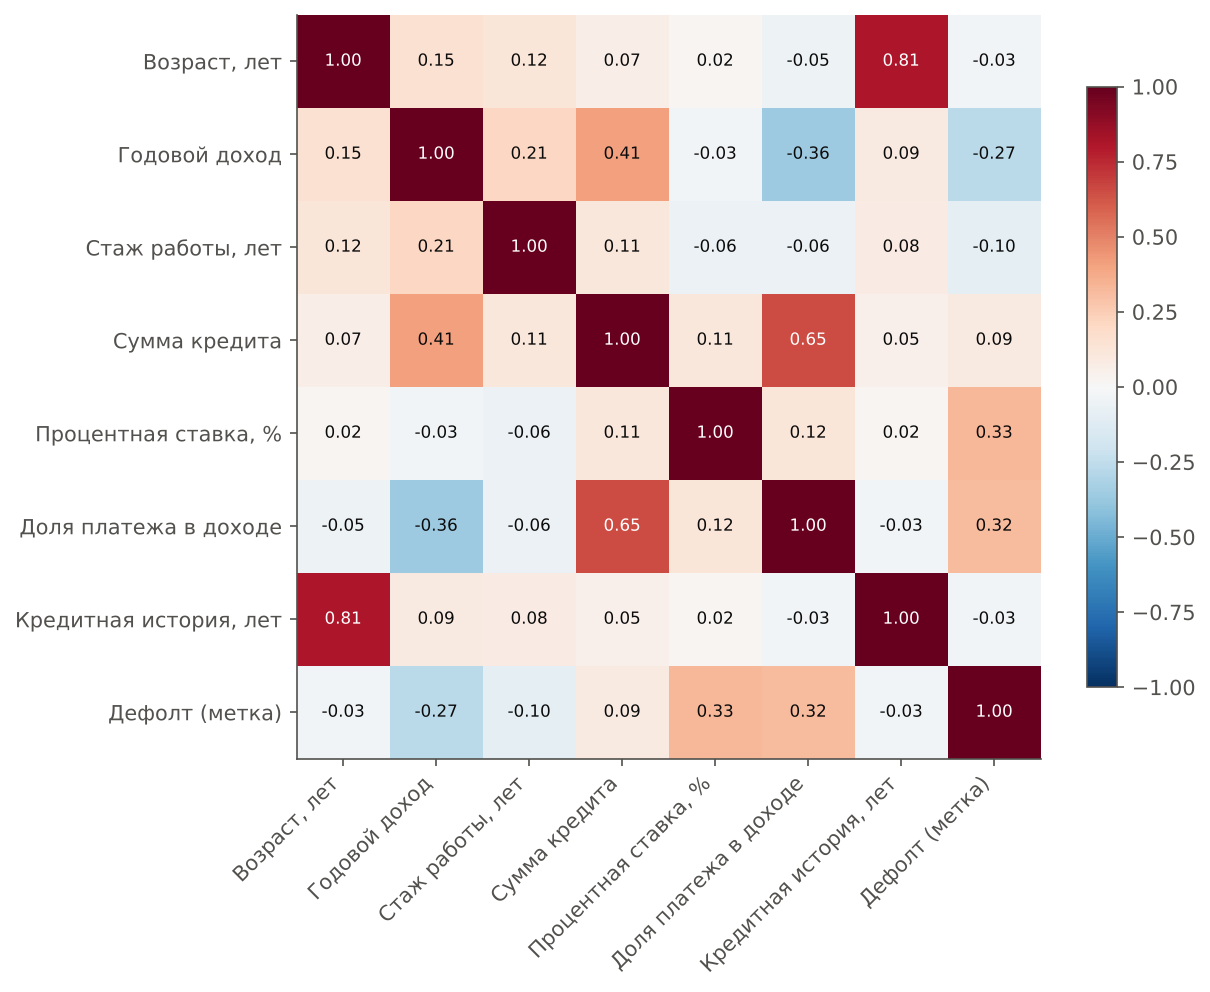

In [8]:
corr = clean[NUMERIC + [TARGET]].corr(method='spearman').round(2)
s['spearman'] = corr.to_dict()
labels = [RU.get(c, 'Дефолт (метка)') for c in corr.columns]
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right'); ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > 0.6 else INK)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8)
save(fig, 'fig_corr.png')

**Вывод:** возраст и длина кредитной истории связаны сильно (0,81) — признаки частично дублируют друг друга, поэтому вводим отношение `credit_hist_to_age`. Доля платежа вычисляется из суммы и дохода и связана с ними. С дефолтом сильнее всего связаны доля платежа, ставка и доход. Мультиколлинеарность важна для линейной модели, для деревьев — нет.

## 6. Признаки с риском утечки

**Вопрос:** какие признаки неизвестны в момент предсказания или фактически раскрывают целевую переменную?

In [9]:
rate_by_grade = df.groupby('loan_grade').loan_int_rate.median().round(2)
print('Медианная ставка по рейтингу займа:'); print(rate_by_grade.to_dict())
print('Медианная ставка по классу:', df.groupby(TARGET).loan_int_rate.median().to_dict())

Медианная ставка по рейтингу займа:
{'A': 7.49, 'B': 10.99, 'C': 13.48, 'D': 15.33, 'E': 16.7, 'F': 18.53, 'G': 20.16}
Медианная ставка по классу: {0: 10.59, 1: 13.49}


**Вывод:** признака, прямо раскрывающего метку, нет. Но рейтинг займа и ставку назначает сам кредитор по своей оценке риска: ставка монотонно растет от A к G. Если модель применяется **до** назначения рейтинга и ставки, эти признаки в момент предсказания неизвестны и их нужно исключить. В проекте принят сценарий оценки после назначения; в ПР3 для сравнения обучается модель без них. `loan_percent_income` рассчитывается из известных в момент заявки суммы и дохода — утечкой не является.

## 7. Проверка предметных гипотез

**H1.** Доля дефолтов растет с ростом долговой нагрузки (доли платежа в доходе).

Спирмен: 0.319, p = 0.00e+00


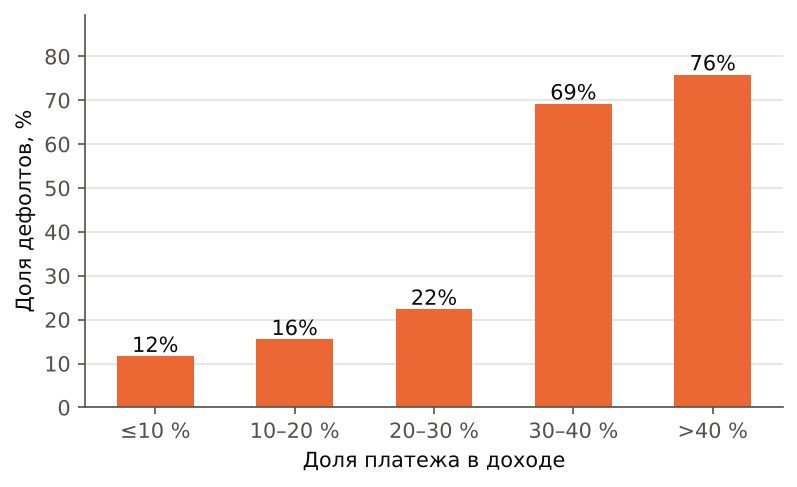

In [10]:
h = {}
grp = pd.cut(df.loan_percent_income, bins=[0, 0.1, 0.2, 0.3, 0.4, 1.0],
             labels=['≤10 %', '10–20 %', '20–30 %', '30–40 %', '>40 %'], include_lowest=True)
r1 = df.groupby(grp, observed=True)[TARGET].agg(['mean', 'size'])
rho, pval = stats.spearmanr(df.loan_percent_income, df[TARGET])
h['H1'] = {'by_bin': {k: {'rate': round(float(v['mean']), 4), 'n': int(v['size'])} for k, v in r1.iterrows()},
           'spearman': round(float(rho), 3), 'p': float(pval)}
print(f'Спирмен: {rho:.3f}, p = {pval:.2e}')

fig, ax = plt.subplots(figsize=(6, 3.4))
bars = ax.bar(r1.index.astype(str), r1['mean'] * 100, color=C_DEF, width=0.55)
for b, v in zip(bars, r1['mean']):
    ax.text(b.get_x() + b.get_width() / 2, v * 100 + 1, f'{v:.0%}', ha='center', color=INK)
ax.set_xlabel('Доля платежа в доходе'); ax.set_ylabel('Доля дефолтов, %')
ax.set_ylim(0, r1['mean'].max() * 118); ax.grid(axis='x', visible=False)
save(fig, 'fig_h1_burden.png')

**Вывод:** подтверждается. При доле платежа выше 30 % дефолтов в разы больше — отсюда признак `high_burden`.

**H2.** Арендаторы жилья дефолтят чаще, чем собственники и заемщики с ипотекой.

In [11]:
sub = df[df.person_home_ownership.isin(['RENT', 'OWN', 'MORTGAGE'])]
chi2, p2, _, _ = stats.chi2_contingency(pd.crosstab(sub.person_home_ownership == 'RENT', sub[TARGET]))
h['H2'] = {'rate_rent': round(float(sub[sub.person_home_ownership == 'RENT'][TARGET].mean()), 4),
           'rate_other': round(float(sub[sub.person_home_ownership != 'RENT'][TARGET].mean()), 4),
           'chi2': round(float(chi2), 1), 'p': float(p2)}
h['H2']

{'rate_rent': 0.3181, 'rate_other': 0.1191, 'chi2': 1119.5, 'p': 1.8894311640710806e-245}

**Вывод:** подтверждается (хи-квадрат, p < 0,001), тип жилья сохраняем как признак.

**H3.** Дефолт в кредитной истории повышает риск нового дефолта.

In [12]:
chi2, p3, _, _ = stats.chi2_contingency(pd.crosstab(df.cb_person_default_on_file, df[TARGET]))
h['H3'] = {'rate_Y': round(float(df[df.cb_person_default_on_file == 'Y'][TARGET].mean()), 4),
           'rate_N': round(float(df[df.cb_person_default_on_file == 'N'][TARGET].mean()), 4),
           'chi2': round(float(chi2), 1), 'p': float(p3)}
h['H3']

{'rate_Y': 0.3873, 'rate_N': 0.1853, 'chi2': 668.7, 'p': 1.9298214947583594e-147}

**Вывод:** подтверждается — признак `prev_default`.

**H4.** Возраст почти не влияет на риск дефолта.

In [13]:
a0, a1 = clean[clean[TARGET] == 0].person_age, clean[clean[TARGET] == 1].person_age
u, p4 = stats.mannwhitneyu(a0, a1)
rho4, _ = stats.spearmanr(clean.person_age, clean[TARGET])
groups = clean.assign(g=pd.cut(clean.person_age, P['features']['age_bins'], labels=P['features']['age_labels']))
h['H4'] = {'median_age_0': float(a0.median()), 'median_age_1': float(a1.median()), 'spearman': round(float(rho4), 3),
           'p': float(p4), 'by_group': rate_table(groups, 'g')}
h['H4']

{'median_age_0': 26.0, 'median_age_1': 26.0, 'spearman': -0.034, 'p': 2.310604766399736e-06, 'by_group': {'<=25': {'default_rate': 0.2337, 'n': 9183}, '26-35': {'default_rate': 0.208, 'n': 8260}, '36-50': {'default_rate': 0.2079, 'n': 1924}, '50+': {'default_rate': 0.2809, 'n': 178}}}

**Вывод:** подтверждается: медианы возраста совпадают, корреляция близка к нулю (значимость формальная из-за объема выборки). Связь слабая и нелинейная — используем возрастные группы `age_group`.

**H5.** Пропуск процентной ставки не связан с дефолтом (пропуски случайны).

In [14]:
miss = df.loan_int_rate.isna()
chi2, p5, _, _ = stats.chi2_contingency(pd.crosstab(miss, df[TARGET]))
h['H5'] = {'rate_missing': round(float(df[miss][TARGET].mean()), 4),
           'rate_present': round(float(df[~miss][TARGET].mean()), 4), 'p': float(p5)}
h['rate_median_by_target'] = df.groupby(TARGET).loan_int_rate.median().to_dict()
h['rate_by_grade_median'] = rate_by_grade.to_dict()
s['hypotheses'] = h
h['H5']

{'rate_missing': 0.2104, 'rate_present': 0.2218, 'p': 0.2762016289522256}

**Вывод:** подтверждается (p > 0,05): пропуски ставки можно заполнять медианой, флаг `int_rate_missing` оставляем для контроля.

## Итоги и сохранение сводки

In [15]:
Path('reports/eda_summary.json').write_text(json.dumps(s, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
print('Сохранено: reports/eda_summary.json и', len(list(FIG.glob('*.png'))), 'рисунков в reports/figures')

Сохранено: reports/eda_summary.json и 5 рисунков в reports/figures


**Итог анализа:** умеренный дисбаланс классов (около 22 % дефолтов); пропуски, дубликаты, невозможные и несогласованные значения → требования к качеству DQ-01…DQ-10; сильная связь риска с долговой нагрузкой, рейтингом, типом жилья и прошлым дефолтом → план признаков (Таблица 2.9 отчета); возможная утечка через рейтинг и ставку → сравнение моделей с ними и без них в ПР3.